# Supervised batch classifier (Project 2, BRPMM)

`inspecting.ipynb` trains **one-class** anomaly detectors on accepted batches only. This notebook trains
**supervised** classifiers on both classes, using the labelled calibration batches.

Steps:
1. Load the data and labels. The borderline batches A_101–A_104 count as rejected, as in `inspecting.ipynb`.
2. Build one row per batch, from two views: hand-made features and a coarse 50-step trajectory.
3. Compare models with **repeated stratified 5-fold CV**, with the anomaly model (PCA T²) as a baseline on the *same* folds.
4. Estimate leaderboard F1 honestly: the threshold is picked by an *inner* CV inside each outer training fold.
5. Fit on all calibration batches, predict the test batches and save CSVs to `team-workspace/submissions/`
   (outside the public repo). **Nothing is submitted.**

The leaderboard treats **accepted as the positive class**, so all F1 / precision / recall numbers below do the same.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

sys.path.insert(0, str(Path.cwd().parent / "src"))   # notebooks/ -> src/
from data_loader import INPUT_DIR, WORKSPACE, load_long, load_variables
from features import build_features, drop_constant
from models import pca_monitor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import rankdata
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from lightgbm import LGBMClassifier

In [2]:
# DATASET SWITCH: change this one line, then Run All
SWITCH = "A"  # "A" or "B"

BORDERLINE = ["A_101", "A_102", "A_103", "A_104"]   # brief: rejected, but borderline
FEATURES = load_variables(SWITCH)
print(f"process {SWITCH}: {len(FEATURES)} sensors")

# predictions go to the shared team folder, NOT the repo (the repo is public)
SUB_DIR = WORKSPACE / "submissions"
SUB_DIR.mkdir(parents=True, exist_ok=True)
print("submission files ->", SUB_DIR)

process A: 11 sensors
submission files -> /home/renku/work/team-workspace/submissions


## 1. Data and labels

In [3]:
df = load_long(SWITCH, "calibration")
df_test = load_long(SWITCH, "test")

labels = pd.read_csv(INPUT_DIR / f"process {SWITCH}/calibration data/calibration_labels.csv").set_index("batch_id")["label"]
fix = labels.index.isin(BORDERLINE) & (labels != "rejected")
print("relabelled as rejected (borderline):", labels.index[fix].tolist())
labels[labels.index.isin(BORDERLINE)] = "rejected"
labels.value_counts()

relabelled as rejected (borderline): ['A_101', 'A_103']


label
accepted    119
rejected     42
Name: count, dtype: int64

## 2. Features: one row per batch

* **feat**: `features.build_features` (summary, trend, dynamics and segment statistics) plus the extra
  features from `inspecting.ipynb`: phase means, robust quantiles, roughness, worst rolling volatility,
  sensor–sensor correlations, and batch length.
* **traj**: each batch resampled to 50 equal blocks (block means), so one column per (sensor, block).
  This captures *when* in the batch something happens.

In [4]:
def extra_features(d, features):
    g = d.groupby("batch_id")
    t_norm = d["t"] / g["t"].transform("max")
    phase = pd.cut(t_norm, [-0.01, 0.2, 0.8, 1.0], labels=["start", "mid", "end"])
    ph = d.groupby(["batch_id", phase], observed=True)[features].mean().unstack()
    ph.columns = [f"{f}_ph_{p}" for f, p in ph.columns]

    q = g[features].quantile([0.05, 0.95]).unstack()
    q.columns = [f"{f}_q{int(round(p * 100))}" for f, p in q.columns]

    same = d["batch_id"].eq(d["batch_id"].shift())
    rough = d[features].diff().where(same).abs().groupby(d["batch_id"]).mean()
    rough.columns = [f"{f}_rough" for f in features]

    vol = g[features].rolling(50).std().groupby(level=0).max()
    vol.columns = [f"{f}_maxvol" for f in features]

    c = g[features].corr().unstack()
    pairs = [(a, b) for i, a in enumerate(features) for b in features[i + 1:]]
    corr = c[pairs].fillna(0)
    corr.columns = [f"corr_{a}__{b}" for a, b in pairs]

    out = pd.concat([ph, q, rough, vol, corr], axis=1)
    out["length"] = g.size()
    return out


def trajectory(d, features, L=50):
    rows = {}
    for b, gg in d.sort_values(["batch_id", "t"]).groupby("batch_id"):
        a = gg[features].to_numpy(dtype=np.float64)
        rows[b] = np.stack([blk.mean(axis=0) for blk in np.array_split(a, L)]).T.ravel()   # sensor-major
    cols = [f"{f}_tr{i:02d}" for f in features for i in range(L)]
    return pd.DataFrame.from_dict(rows, orient="index", columns=cols)


def make_views(d):
    feat = build_features(d)
    ext = extra_features(d, FEATURES)
    feat = feat.join(ext[ext.columns.difference(feat.columns)])   # never duplicate a column name
    return feat, trajectory(d, FEATURES)


feat, traj = make_views(df)
feat_test, traj_test = make_views(df_test)

# same columns for train and test; drop columns that are constant in calibration (process B has some)
feat, feat_test = drop_constant(feat, feat_test[feat.columns])
traj, traj_test = drop_constant(traj, traj_test[traj.columns])

ids = labels.index.intersection(feat.index)
assert len(ids) == len(labels) == len(feat), "every calibration batch needs features and a label"
feat, traj = feat.loc[ids], traj.loc[ids]
traj_test = traj_test.loc[feat_test.index]

views = {"feat": feat, "feat+traj": feat.join(traj)}
views_test = {"feat": feat_test, "feat+traj": feat_test.join(traj_test)}
y = (labels.loc[ids] == "rejected").astype(int).to_numpy()    # 1 = rejected (the model's target)

for k in views:
    print(f"{k:<10} train {views[k].shape}  test {views_test[k].shape}  NaN train/test:",
          int(views[k].isna().sum().sum()), int(views_test[k].isna().sum().sum()))
print("rejected share in calibration:", y.mean().round(3))

feat       train (161, 332)  test (161, 332)  NaN train/test: 0 0
feat+traj  train (161, 882)  test (161, 882)  NaN train/test: 0 0
rejected share in calibration: 0.261


## 3. Models

Every model outputs a score where **higher = more likely rejected**. The PCA T² anomaly detector from
`models.py` (the method behind our submission) is fitted on the *accepted batches of each training fold only*,
so it is scored on exactly the same splits as the supervised models.

In [5]:
imp = lambda: SimpleImputer(strategy="median")   # safety net; the feature tables have no NaNs today

def svm():
    return make_pipeline(imp(), StandardScaler(), SVC(C=1, gamma="scale", class_weight="balanced"))

MODELS = {
    "SVM rbf":        svm,
    "ExtraTrees":     lambda: make_pipeline(imp(), ExtraTreesClassifier(1000, class_weight="balanced", n_jobs=-1, random_state=0)),
    "LightGBM":       lambda: make_pipeline(imp(), LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=7,
                                  min_child_samples=5, subsample=0.8, subsample_freq=1, colsample_bytree=0.3,
                                  class_weight="balanced", verbose=-1, random_state=0)),
    "LogReg L1":      lambda: make_pipeline(imp(), StandardScaler(), LogisticRegression(C=0.3, penalty="l1",
                                  solver="liblinear", class_weight="balanced")),
}


def fit_score(make, X_tr, y_tr, X_te):
    """Fit a supervised model, return scores for X_te (higher = rejected)."""
    m = make().fit(X_tr, y_tr)
    return m.decision_function(X_te) if hasattr(m, "decision_function") else m.predict_proba(X_te)[:, 1]


def fit_score_anomaly(X_tr, y_tr, X_te, n_components=15):
    """Baseline: PCA T² trained on the accepted training batches only."""
    m = Pipeline([("imp", imp())] + pca_monitor(n_components, "T2").steps).fit(X_tr[y_tr == 0])
    return -m.score_samples(X_te)

In [6]:
N_SPLITS, N_REPEATS = 5, 5
splits = list(RepeatedStratifiedKFold(n_splits=N_SPLITS, n_repeats=N_REPEATS, random_state=0).split(ids, y))


def oof_scores(fn, X):
    """Out-of-fold scores, one row per CV repeat: shape (N_REPEATS, n_batches).

    Scores are turned into within-fold ranks (0..1], so that folds and models are comparable
    and can be averaged (used for the hybrid below).
    """
    X = X.to_numpy(dtype=np.float64)
    out = np.full((N_REPEATS, len(y)), np.nan)
    for k, (tr, te) in enumerate(splits):
        s = fn(X[tr], y[tr], X[te])
        out[k // N_SPLITS, te] = rankdata(s) / len(s)
    assert not np.isnan(out).any()
    return out


oof = {}
oof["Anomaly PCA T² (baseline) | feat"] = oof_scores(fit_score_anomaly, views["feat"])
for view in views:
    for name, make in MODELS.items():
        print("running", name, "|", view, "...")
        oof[f"{name} | {view}"] = oof_scores(lambda a, b, c, make=make: fit_score(make, a, b, c), views[view])
oof["Hybrid: 0.75·SVM + 0.25·T² (ranks)"] = (0.75 * oof["SVM rbf | feat+traj"]
                                              + 0.25 * oof["Anomaly PCA T² (baseline) | feat"])

running SVM rbf | feat ...
running ExtraTrees | feat ...


running LightGBM | feat ...


running LogReg L1 | feat ...


running SVM rbf | feat+traj ...


running ExtraTrees | feat+traj ...


running LightGBM | feat+traj ...


running LogReg L1 | feat+traj ...


In [7]:
def summarize(o):
    auc = [roc_auc_score(y, r) for r in o]
    ap = [average_precision_score(y, r) for r in o]
    return {"ROC AUC": np.mean(auc), "ROC AUC sd": np.std(auc), "PR AUC (rejected)": np.mean(ap), "PR AUC sd": np.std(ap)}

results = pd.DataFrame({k: summarize(v) for k, v in oof.items()}).T.sort_values("PR AUC (rejected)", ascending=False)
print(f"process {SWITCH}, {N_REPEATS}x repeated stratified {N_SPLITS}-fold CV (sd = across repeats)")
results.style.format(precision=3)

process A, 5x repeated stratified 5-fold CV (sd = across repeats)


,ROC AUC,ROC AUC sd,PR AUC (rejected),PR AUC sd
Hybrid: 0.75·SVM + 0.25·T² (ranks),0.894,0.007,0.769,0.020
SVM rbf | feat+traj,0.888,0.007,0.732,0.014
SVM rbf | feat,0.875,0.011,0.722,0.004
ExtraTrees | feat,0.828,0.020,0.681,0.028
Anomaly PCA T² (baseline) | feat,0.832,0.013,0.651,0.034
ExtraTrees | feat+traj,0.811,0.024,0.644,0.038
LightGBM | feat,0.756,0.025,0.534,0.063
LightGBM | feat+traj,0.744,0.024,0.506,0.055
LogReg L1 | feat+traj,0.647,0.038,0.460,0.049
LogReg L1 | feat,0.655,0.030,0.458,0.042


**How to read this.** ROC AUC and PR AUC do not depend on a threshold, so they are the fairest way to compare
models. The *sd* only reflects how the folds were shuffled. With so few rejected batches (40 in A, 5 in B),
differences of a few hundredths are within noise.

## 4. Honest F1 (the leaderboard metric)

A score needs a threshold before it becomes a label. If the threshold is picked on the same out-of-fold scores
that are then evaluated, F1 comes out optimistic. So, for every outer fold:
1. run an inner 5-fold CV on the outer *training* batches only and pick the F1-best threshold there;
2. fit on the whole outer training set and apply that threshold to the held-out batches.

Metrics follow the leaderboard: **positive = accepted**.

In [8]:
def lb_metrics(y_rej, pred_rej):
    """Leaderboard metrics, accepted = positive. Inputs use 1 = rejected."""
    yt, yp = 1 - np.asarray(y_rej), 1 - np.asarray(pred_rej)
    return {"accuracy": accuracy_score(yt, yp), "precision": precision_score(yt, yp, zero_division=0),
            "recall": recall_score(yt, yp, zero_division=0), "F1": f1_score(yt, yp, zero_division=0)}


def best_threshold(scores, y_rej):
    """Threshold on raw scores maximising leaderboard F1; score > thr -> rejected.

    Candidates are midpoints between sorted unique scores (plus both ends), so the threshold
    is never sitting exactly on a training score.
    """
    u = np.unique(scores)
    cands = np.r_[u[0] - 1e-9, (u[:-1] + u[1:]) / 2, u[-1] + 1e-9]
    f1 = [lb_metrics(y_rej, (scores > t).astype(int))["F1"] for t in cands]
    return cands[int(np.argmax(f1))]


def inner_oof_raw(fn, X, y_, seed=0):
    """Raw (not ranked) out-of-fold scores from a single 5-fold CV."""
    out = np.full(len(y_), np.nan)
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y_):
        out[te] = fn(X[tr], y_[tr], X[te])
    return out


def nested_f1(fn, X):
    X = X.to_numpy(dtype=np.float64)
    rows, preds = [], np.zeros((N_REPEATS, len(y)), dtype=int)
    for k, (tr, te) in enumerate(splits):
        thr = best_threshold(inner_oof_raw(fn, X[tr], y[tr], seed=k), y[tr])
        preds[k // N_SPLITS, te] = (fn(X[tr], y[tr], X[te]) > thr).astype(int)
    for r in range(N_REPEATS):        # metrics per repeat, on all batches at once (like the leaderboard)
        rows.append(lb_metrics(y, preds[r]))
    return pd.DataFrame(rows).agg(["mean", "std"]).T

In [9]:
# Final model per process, picked from the CV table above:
#   A: SVM is clearly best among the supervised models.
#   B: only 5 rejected batches; ExtraTrees / LightGBM / L1-LogReg on "feat" all separate them perfectly,
#      while the SVM on feat+traj is the weakest model, so B uses ExtraTrees.
FINAL = {"A": ("SVM rbf", "feat+traj"), "B": ("ExtraTrees", "feat")}
FINAL_MODEL, FINAL_VIEW = FINAL[SWITCH]
final_fn = lambda a, b, c: fit_score(MODELS[FINAL_MODEL], a, b, c)
print("final model:", FINAL_MODEL, "|", FINAL_VIEW)

nested = {"Anomaly PCA T² (baseline) | feat": nested_f1(fit_score_anomaly, views["feat"])}
for name, view in dict.fromkeys([("SVM rbf", "feat+traj"), (FINAL_MODEL, FINAL_VIEW)]):
    nested[f"{name} | {view}"] = nested_f1(lambda a, b, c, m=MODELS[name]: fit_score(m, a, b, c), views[view])
# reference: label everything "accepted"
nested["(all accepted)"] = pd.DataFrame([lb_metrics(y, np.zeros_like(y))]).agg(["mean", "std"]).T.fillna(0)

f1_table = pd.concat({k: v["mean"] for k, v in nested.items()}, axis=1).T
f1_table["F1 sd"] = [v.loc["F1", "std"] for v in nested.values()]
f1_table.style.format(precision=3)

final model: SVM rbf | feat+traj


,accuracy,precision,recall,F1,F1 sd
Anomaly PCA T² (baseline) | feat,0.810,0.819,0.955,0.881,0.007
SVM rbf | feat+traj,0.837,0.880,0.903,0.891,0.014
(all accepted),0.739,0.739,1.000,0.850,0.000


These are honest estimates for batches the model has not seen. They come from training on 80% of the calibration
data, so the final model (trained on 100%) should do slightly better. For reference, our anomaly submission scored
F1 0.922 on the process A test set.

## 5. Final model → test predictions (saved to CSV, not submitted)

The model and view come from `FINAL` (section 4).

In [10]:
Xc = views[FINAL_VIEW].to_numpy(dtype=np.float64)
Xt = views_test[FINAL_VIEW][views[FINAL_VIEW].columns].to_numpy(dtype=np.float64)   # same column order

# threshold: F1-best on out-of-fold raw scores, pooled over several 5-fold CVs (raw scores keep the model's own scale)
oof_raw = np.concatenate([inner_oof_raw(final_fn, Xc, y, seed=s) for s in range(N_REPEATS)])
y_rep = np.tile(y, N_REPEATS)
THR = best_threshold(oof_raw, y_rep)
print(f"{FINAL_MODEL}: threshold on its score = {THR:.4f}")
print("out-of-fold metrics at this threshold (slightly optimistic, see section 4):",
      {k: round(v, 3) for k, v in lb_metrics(y_rep, (oof_raw > THR).astype(int)).items()})

test_scores = pd.Series(final_fn(Xc, y, Xt), index=views_test[FINAL_VIEW].index)   # fit on ALL calibration batches
pred = np.where(test_scores > THR, "rejected", "accepted")

SVM rbf: threshold on its score = 0.2363
out-of-fold metrics at this threshold (slightly optimistic, see section 4): {'accuracy': 0.845, 'precision': 0.883, 'recall': 0.911, 'F1': 0.897}


label
accepted    127
rejected     34
Name: count, dtype: int64
predicted rejected share on test: 0.21   (calibration: 0.26)


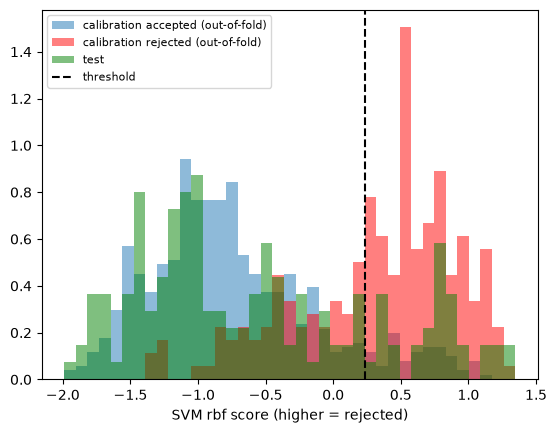

saved /home/renku/work/team-workspace/submissions/submission_supervised_A.csv (not submitted)


In [11]:
submission = pd.DataFrame({"batch_id": test_scores.index, "label": pred}).sort_values("batch_id")
print(submission["label"].value_counts())
print(f"predicted rejected share on test: {(pred == 'rejected').mean():.2f}   (calibration: {y.mean():.2f})")

bins = np.linspace(min(oof_raw.min(), test_scores.min()), max(oof_raw.max(), test_scores.max()), 40)
plt.hist(oof_raw[y_rep == 0], bins=bins, alpha=0.5, density=True, label="calibration accepted (out-of-fold)")
plt.hist(oof_raw[y_rep == 1], bins=bins, alpha=0.5, density=True, color="red", label="calibration rejected (out-of-fold)")
plt.hist(test_scores, bins=bins, alpha=0.5, density=True, color="green", label="test")
plt.axvline(THR, color="k", ls="--", label="threshold")
plt.xlabel(f"{FINAL_MODEL} score (higher = rejected)"); plt.legend(fontsize=8); plt.show()

OUT = SUB_DIR / f"submission_supervised_{SWITCH}.csv"
submission.to_csv(OUT, index=False)
print("saved", OUT, "(not submitted)")

### Compare with the anomaly submission

How often does the supervised model agree with the `submission_{SWITCH}.csv` written by `inspecting.ipynb`?
The batches where the two disagree are the ones worth inspecting by eye.

In [12]:
prev_path = Path(f"submission_{SWITCH}.csv")
if prev_path.exists():
    prev = pd.read_csv(prev_path).set_index("batch_id")["label"]
    cmp = submission.set_index("batch_id")["label"].rename("supervised").to_frame().join(prev.rename("anomaly"))
    print("agreement:", (cmp["supervised"] == cmp["anomaly"]).mean().round(3))
    display(pd.crosstab(cmp["anomaly"], cmp["supervised"]))
    print("batches where the two disagree:", cmp.index[cmp["supervised"] != cmp["anomaly"]].size)
else:
    print(f"{prev_path} not found; run inspecting.ipynb with SWITCH = {SWITCH!r} first to compare.")

agreement: 0.882


supervised,accepted,rejected
anomaly,,
accepted,122,14
rejected,5,20


batches where the two disagree: 19


## 6. Combined submission file (A + B), leaderboard format (not submitted)

The leaderboard takes **one** file with both processes, in the template's format (`batch_id, project, label`).
Run this notebook once with `SWITCH = "B"` and once with `SWITCH = "A"`. The second run writes
`team-workspace/submissions/submission_supervised.csv`. To submit it, use `submit()` from `Leaderboard_template_project2.ipynb`.

In [13]:
template = pd.read_csv(INPUT_DIR / "BRPMM_template.csv", dtype={"batch_id": str})
parts = {p: SUB_DIR / f"submission_supervised_{p}.csv" for p in ("A", "B")}
missing = [p for p, f in parts.items() if not f.exists()]
if missing:
    print(f"run this notebook with SWITCH = {missing[0]!r} too; then this cell writes the combined file")
else:
    preds = pd.concat([pd.read_csv(f, dtype={"batch_id": str}) for f in parts.values()]).set_index("batch_id")["label"]
    # checks: exactly the template's batches, no duplicates, only valid labels
    assert preds.index.is_unique, "duplicate batch_id"
    assert set(preds.index) == set(template["batch_id"]), "batch ids differ from the template"
    assert set(preds.unique()) <= {"accepted", "rejected"}, "unexpected label"
    combined = template[["batch_id", "project"]].assign(label=template["batch_id"].map(preds).values)
    assert combined["label"].notna().all() and list(combined.columns) == list(template.columns)
    OUT_ALL = SUB_DIR / "submission_supervised.csv"
    combined.to_csv(OUT_ALL, index=False)
    print("saved", OUT_ALL, "(not submitted)")
    print(combined.groupby(["project", "label"]).size())

saved /home/renku/work/team-workspace/submissions/submission_supervised.csv (not submitted)
project  label   
A        accepted    127
         rejected     34
B        accepted     35
         rejected      5
dtype: int64
